In [ ]:
from download_dataset import fetch_training_data
from json_to_pd import load_telemetry_dataframe
import pandas as pd
import sklearn
import matplotlib.pyplot as plt

In [ ]:
# Сгрузить данные

# fetch_training_data(
#     base_url="http://127.0.0.1:8000",
#     robot_id="robot_1_sim",
#     duration_s=600,
#     max_points=20000,
# )

GET /api/robots -> 200: [{"id":"robot_1_sim","online":true,"first_seen_ms":1793985794898,"last_seen_ms":1795627230809,"last_point_ms":1795627230756,"total_points":244725,"total_batches":2454,"last_point":{"timestamp_ms":1795627230756,"status":"OK","status_message":null,"pose":{"x":524.0885291337886,"y":339.1493992089808,"yaw":0.19853486415088106},"cmd_vel":{"linear_x":0.15,"angular_z":0.7853981633974483},"odom_vel":{"linear_x":0.15893208987278293,"angular_z":0.7832432717011918}}}]
Выгружено точек: 11773 из 11773 (stride=1)
Сохранено в train_dataset.json


In [ ]:
df = load_telemetry_dataframe(json_path="./train_dataset.json")

In [ ]:
df

,timestamp_ms,status,x,y,yaw,cmd_v,cmd_w,odom_v,odom_w,prev_odom_v,prev_odom_w
0,1795626633606,OK,361.283219,245.477258,-0.132741,0.594398,0.000000,0.604796,0.012168,0.591083,-0.001423
1,1795626633656,OK,361.312651,245.473316,-0.133167,0.597417,0.000000,0.593913,-0.008532,0.604796,0.012168
2,1795626633706,OK,361.342157,245.469363,-0.133157,0.600370,0.000000,0.595391,0.000200,0.593913,-0.008532
3,1795626633756,OK,361.372625,245.465280,-0.133231,0.603253,0.000000,0.614808,-0.001467,0.595391,0.000200
4,1795626633806,OK,361.402882,245.461234,-0.132934,0.606066,0.000000,0.610511,0.005936,0.614808,-0.001467
...,...,...,...,...,...,...,...,...,...,...,...
11767,1795627230556,OK,524.058894,339.145202,0.040260,0.150000,0.785398,0.147177,0.792967,0.161648,0.782366
11768,1795627230606,OK,524.066408,339.145806,0.080169,0.150000,0.785398,0.150753,0.798176,0.147177,0.792967
11769,1795627230656,OK,524.073338,339.146642,0.120153,0.150000,0.785398,0.139612,0.799691,0.150753,0.798176
11770,1795627230706,OK,524.080739,339.147832,0.159373,0.150000,0.785398,0.149909,0.784390,0.139612,0.799691


In [ ]:
from pickle import dump
from sklearn.linear_model import LinearRegression

model_v = LinearRegression().fit(df[["cmd_v", "prev_odom_v"]], df["odom_v"])
model_w = LinearRegression().fit(df[["cmd_w", "prev_odom_w"]], df["odom_w"])

with open("kinematic_models_robot_1_sim.pkl", "wb") as f:
    dump({"model_v": model_v, "model_w": model_w}, f)

print("Веса v:", model_v.coef_, "intercept:", model_v.intercept_)
print("Веса w:", model_w.coef_, "intercept:", model_w.intercept_)


Веса v: [ 1.00068210e+00 -9.38344848e-04] intercept: 5.7681531107134365e-05
Веса w: [ 1.00107821 -0.00130861] intercept: -1.8831516709019724e-05


/home/kslav/projects/misisobot/learning/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


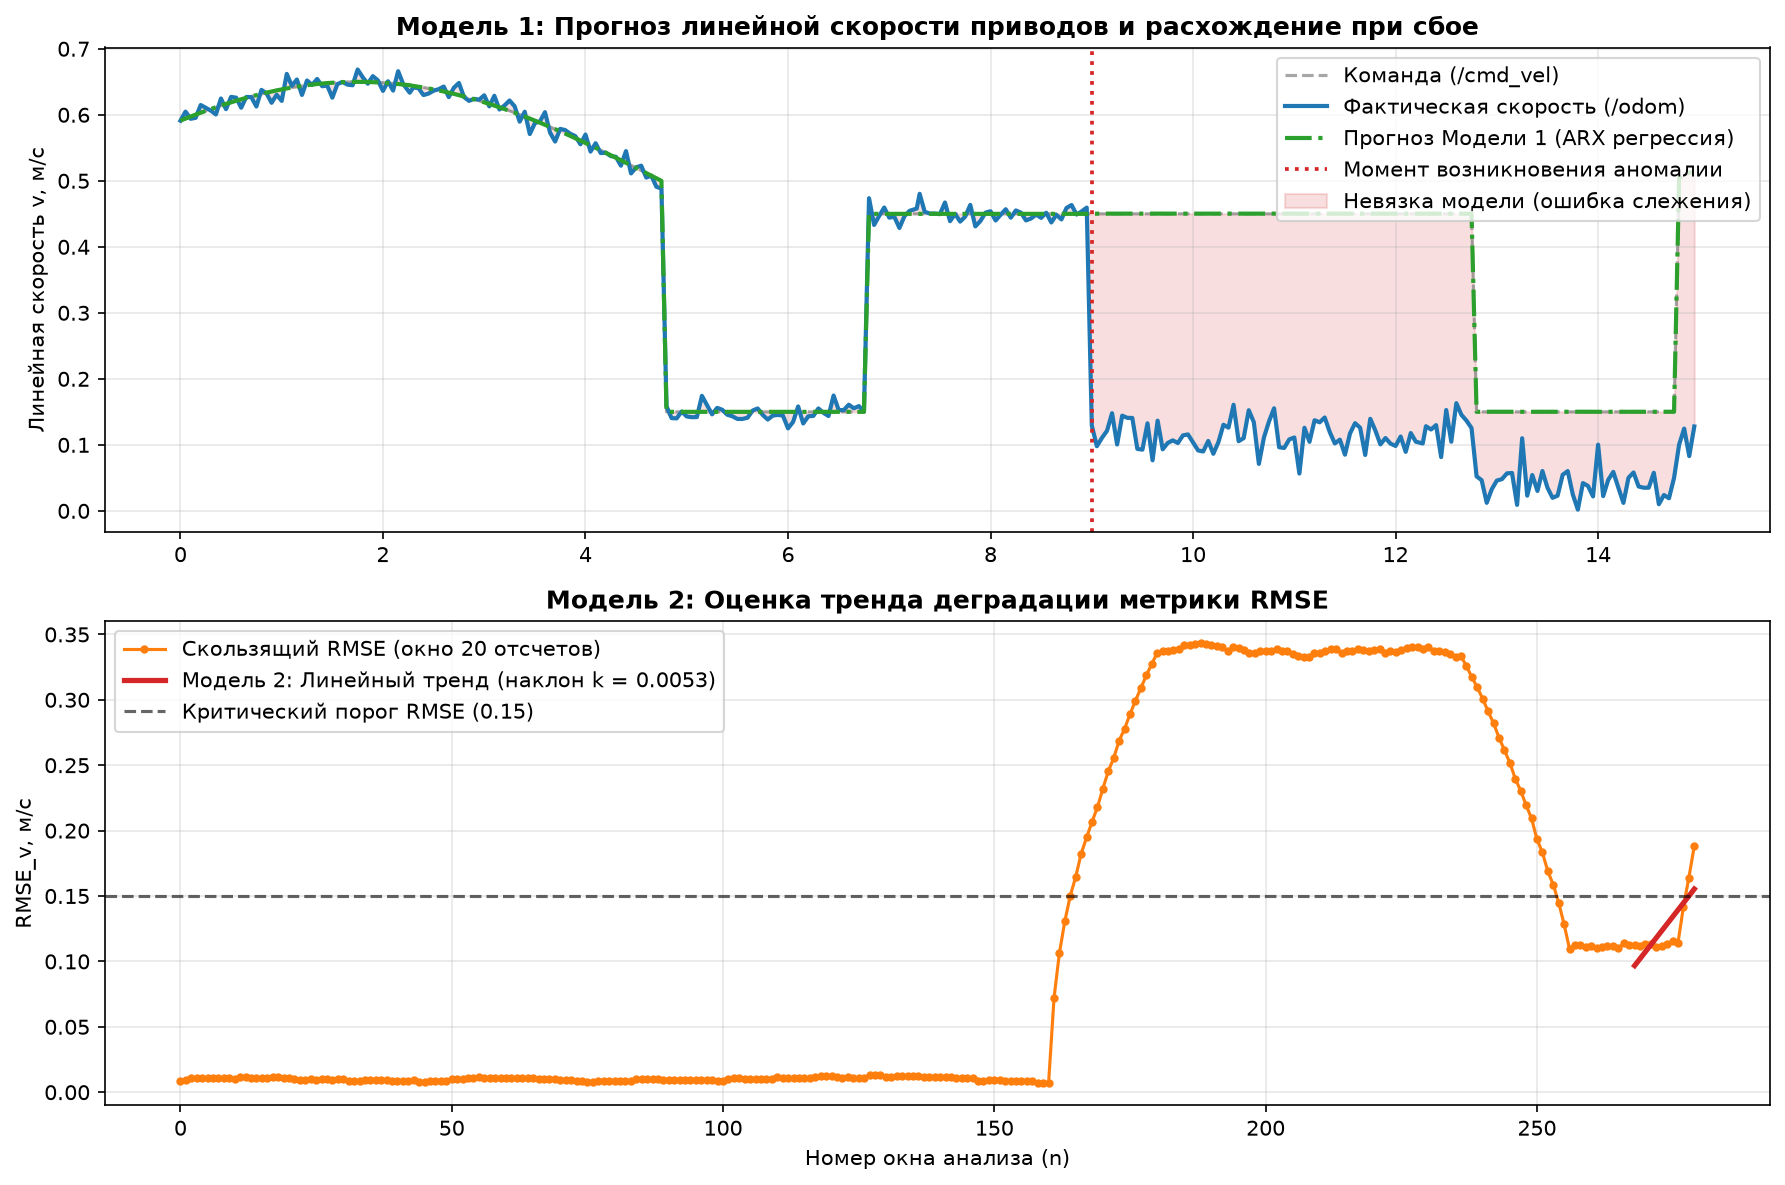

In [ ]:
import json
from pathlib import Path
from pickle import load
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Настройка стиля графиков для отчета
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

# Берем срез ~300 точек для наглядности и имитируем сбой во второй половине среза
df["t_sec"] = (df["t"] - df["t"].iloc[0]) / 1000.0
sample = df.iloc[:300].copy().reset_index(drop=True)
split_idx = 180
sample.loc[split_idx:, "odom_v"] = sample.loc[split_idx:, "odom_v"] * 0.25 + np.random.normal(0, 0.02, len(sample) - split_idx)
sample["prev_odom_v"] = sample["odom_v"].shift(1).bfill()

# Прогноз Модели 1
X_v = sample[["cmd_v", "prev_odom_v"]].values
sample["pred_v"] = model_v.predict(X_v)

# Расчет скользящего RMSE (окно = 20 точек) для Модели 2
window = 20
rmse_series = []
for i in range(window, len(sample)):
    err = sample["odom_v"].iloc[i - window : i] - sample["pred_v"].iloc[i - window : i]
    rmse_series.append(float(np.sqrt(np.mean(err ** 2))))

# Подгонка Модели 2 (линейный тренд на последних 12 окнах при развитии сбоя)
trend_len = 12
y_trend = np.array(rmse_series[-trend_len:])
x_trend = np.arange(len(rmse_series) - trend_len, len(rmse_series)).reshape(-1, 1)
trend_reg = LinearRegression().fit(x_trend, y_trend)
y_trend_line = trend_reg.predict(x_trend)
slope_k = float(trend_reg.coef_[0])

# --- ПОСТРОЕНИЕ ГРАФИКОВ ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), dpi=150)

# График 1: Модель 1 (Прогноз скорости vs Реальность)
ax1.plot(sample["t_sec"], sample["cmd_v"], "--", color="gray", alpha=0.7, label="Команда (/cmd_vel)")
ax1.plot(sample["t_sec"], sample["odom_v"], color="#1f77b4", linewidth=2, label="Фактическая скорость (/odom)")
ax1.plot(sample["t_sec"], sample["pred_v"], color="#2ca02c", linestyle="-.", linewidth=2, label="Прогноз Модели 1 (ARX регрессия)")
ax1.axvline(sample["t_sec"].iloc[split_idx], color="#d62728", linestyle=":", linewidth=1.8, label="Момент возникновения аномалии")
ax1.fill_between(
    sample["t_sec"],
    sample["odom_v"],
    sample["pred_v"],
    color="#d62728",
    alpha=0.15,
    label="Невязка модели (ошибка слежения)"
)
ax1.set_title("Модель 1: Прогноз линейной скорости приводов и расхождение при сбое", fontsize=12, fontweight="bold")
ax1.set_ylabel("Линейная скорость v, м/с")
ax1.legend(loc="upper right", frameon=True)

# График 2: Модель 2 (Скользящий RMSE и линейный тренд)
ax2.plot(range(len(rmse_series)), rmse_series, marker="o", markersize=3, color="#ff7f0e", label="Скользящий RMSE (окно 20 отсчетов)")
ax2.plot(
    x_trend.flatten(),
    y_trend_line,
    color="#d62728",
    linewidth=2.5,
    label=f"Модель 2: Линейный тренд (наклон k = {slope_k:.4f})"
)
ax2.axhline(0.15, color="black", linestyle="--", alpha=0.6, label="Критический порог RMSE (0.15)")
ax2.set_title("Модель 2: Оценка тренда деградации метрики RMSE", fontsize=12, fontweight="bold")
ax2.set_xlabel("Номер окна анализа (n)")
ax2.set_ylabel("RMSE_v, м/с")
ax2.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.show()
